<a href="https://colab.research.google.com/github/herozandn/Classificador-Spam/blob/main/notebook/analise_spam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sbs
import matplotlib.pyplot as plt

# Dados

In [2]:
from google.colab import auth
from google.auth import default
import gspread
import pandas as pd

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# Abrindo a planilha através da URL
sheet_url = 'https://docs.google.com/spreadsheets/d/1Hs5hwXbpj7X55yMqqt4BHfHXSBI6x1prvuzW3jfgbbg/edit?gid=878299360#gid=878299360'
ws = gc.open_by_url(sheet_url).sheet1
df = pd.DataFrame(ws.get_all_records())

In [3]:
df

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5167,Email 5168,2,2,2,3,0,0,32,0,0,...,0,0,0,0,0,0,0,0,0,0
5168,Email 5169,35,27,11,2,6,5,151,4,3,...,0,0,0,0,0,0,0,1,0,0
5169,Email 5170,0,0,1,1,0,0,11,0,0,...,0,0,0,0,0,0,0,0,0,1
5170,Email 5171,2,7,1,0,2,1,28,2,0,...,0,0,0,0,0,0,0,1,0,1


# Análise Exploratória

In [4]:
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


* O dataset consiste em 5172 emails e 3000 palavras analisadas.

In [5]:
df.columns

Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='object', length=3002)

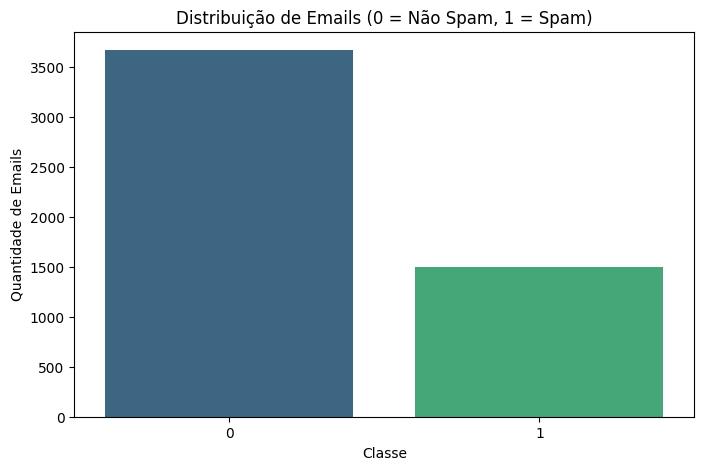

In [6]:
plt.figure(figsize = (8, 5))
sbs.countplot(x='Prediction',
              data=df,
              palette='viridis',
              hue='Prediction',
              legend=False)
plt.title('Distribuição de Emails (0 = Não Spam, 1 = Spam)')
plt.xlabel('Classe')
plt.ylabel('Quantidade de Emails')
plt.show()

In [7]:
df['Prediction'].value_counts()

,count
Prediction,
0,3672
1,1500


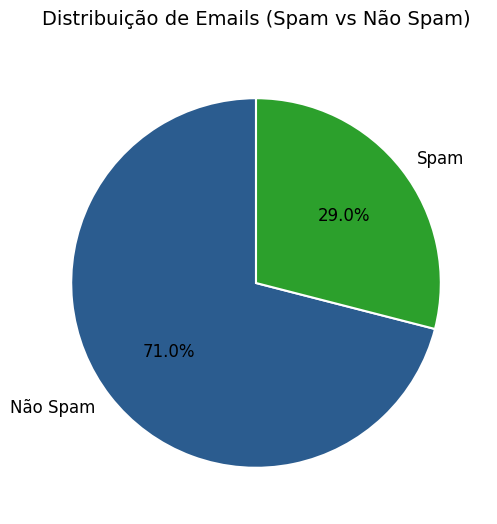

In [21]:
# Contando as classes de predição para o gráfico de pizza
counts = df['Prediction'].value_counts()
labels = ['Não Spam', 'Spam']
colors = ['#2b5c8f', '#2ca02c']

plt.figure(figsize=(6, 6), facecolor='white')
plt.pie(counts,
        labels=labels,
        autopct='%1.1f%%',
        startangle=90,
        colors=colors,
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
        textprops={'fontsize': 12})

plt.title("Distribuição de Emails (Spam vs Não Spam)", fontsize=14, pad=20)
plt.show()

* **Desbalanceamento:** 3672 **não spam** vs 1500 **spam**, isso dá 71% / 29%. Um modelo que sempre responde “não spam” já acerta 71%, e é essa a régua mínima que seu modelo precisa superar.
* Usarei *train_test_split(..., stratify=y)* (mantém a proporção nos dois lados) e focarei em F1 e recall da classe spam, não em acurácia. Na Regressão Logística, teste também class_weight="balanced".

In [8]:
df.duplicated().sum()

np.int64(0)

* Sem duplicados

## Nuvem de palavras

In [9]:
df_spam = df[df['Prediction']==1]

In [10]:
df_spam

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
5,Email 6,4,5,1,4,2,3,45,1,0,...,0,0,0,0,0,0,0,0,0,1
7,Email 8,0,2,2,3,1,2,21,6,0,...,0,0,0,0,0,0,0,1,0,1
16,Email 17,3,1,2,2,0,1,17,0,0,...,0,0,0,0,0,0,0,1,0,1
17,Email 18,36,21,6,14,7,17,194,25,5,...,0,0,0,0,0,0,0,3,0,1
25,Email 26,12,53,2,14,18,14,287,0,2,...,0,0,0,0,0,0,0,6,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5162,Email 5163,2,3,1,2,1,2,32,0,0,...,0,0,0,0,0,0,0,0,0,1
5163,Email 5164,0,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
5166,Email 5167,1,0,1,1,0,0,4,0,0,...,0,0,0,0,0,0,0,0,0,1
5169,Email 5170,0,0,1,1,0,0,11,0,0,...,0,0,0,0,0,0,0,0,0,1


### Decisão de projeto:
Manter as *stopwords* por três motivos:

* Elas podem carregar sinal. Spam costuma abusar de palavras como “you”, “your” e “now”, que muitas listas tratam como stopwords. Se você as apagar, pode perder poder de predição.
* Os modelos já lidam com isso. O Naive Bayes dá a uma palavra que aparece igual nas duas classes um peso quase neutro, e o TF-IDF reduz o peso de palavras comuns a todos os e-mails.
* O dado já veio filtrado de alguma forma. São só 3000 colunas, então alguém já escolheu um vocabulário. Veja quantas stopwords sobraram nele antes de decidir.

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


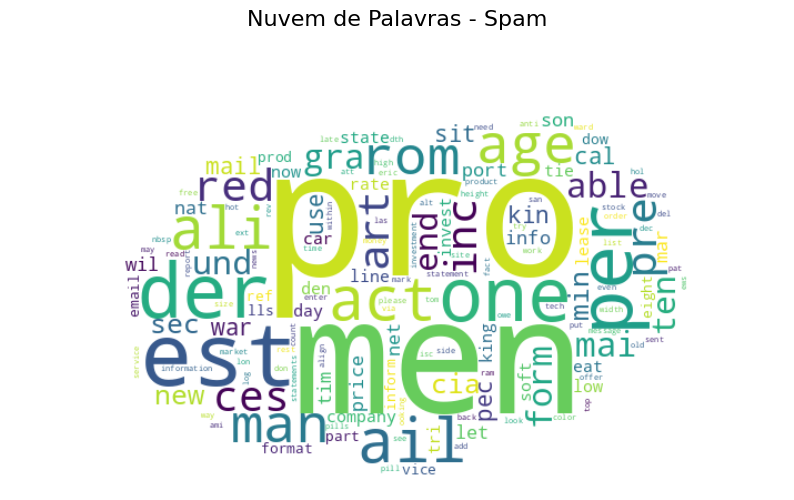

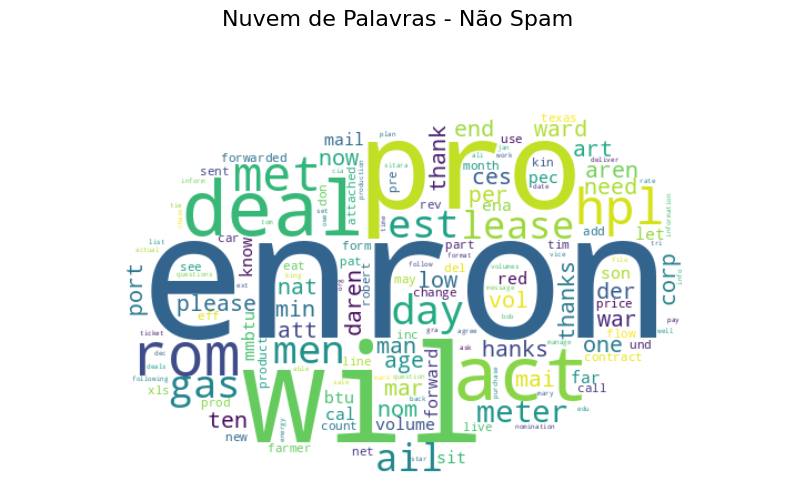

In [18]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

def nuvem(X_classe, titulo):
    # Carrega a imagem de máscara
    mask_image = Image.open("/content/drive/MyDrive/classificadorSpam/data/image-2.png")

    # Convertendo para array numpy
    mask_array = np.array(mask_image)

    # Se a imagem tiver canal alpha (RGBA), substituímos a transparência por branco
    if len(mask_array.shape) == 3 and mask_array.shape[2] == 4:
        # Cria um fundo branco
        white_bg = np.ones_like(mask_array[:, :, :3]) * 255
        alpha = mask_array[:, :, 3:] / 255.0
        # Mescla a imagem com o fundo branco usando o canal alpha
        rgb = mask_array[:, :, :3] * alpha + white_bg * (1 - alpha)
        mask_array = rgb.astype(np.uint8)

    # Se ainda for RGB, convertemos para escala de cinza para criar a máscara binária final
    if len(mask_array.shape) == 3:
        gray = np.mean(mask_array[:, :, :3], axis=2)
        comment_mask = np.zeros_like(gray, dtype=np.uint8)
        # Definimos como 255 (área que NÃO recebe palavras) o que for muito claro/branco
        comment_mask[gray > 200] = 255
        # O que for escuro (desenho) vira 0 (área onde as palavras vão se posicionar)
        comment_mask[gray <= 200] = 0
    else:
        comment_mask = mask_array

    # Remove colunas que não são palavras para não distorcer a nuvem
    colunas_para_remover = ['Email No.', 'Prediction']
    palavras_df = X_classe.drop(columns=[col for col in colunas_para_remover if col in X_classe.columns])

    # Somamos a frequência de cada termo
    freq = palavras_df.sum()

    # Conjunto de Stopwords para filtrar
    stopwords_set = set(STOPWORDS)
    # Adicionamos termos específicos do dataset ou abreviações que aparecem muito mas não trazem significado
    stopwords_set.update(['ect', 'hou', 'com', 'will', 'subject', 'extracted', 'http', 'html', 'font'])

    # FILTRO: Remove stopwords e termos com menos de 3 caracteres
    indices_filtrados = [word for word in freq.index if len(word) > 2 and word.lower() not in stopwords_set]
    freq_filtrada = freq[indices_filtrados]

    # Criamos a nuvem com fundo branco e a máscara binária corrigida
    wc = WordCloud(max_font_size=160,
                   margin=2,
                   background_color="white",
                   mask=comment_mask,
                   contour_width=1,
                   contour_color='white',
                   max_words=150).generate_from_frequencies(freq_filtrada.to_dict())

    # Criando a figura explicitamente com fundo branco para evitar o quadriculado
    fig = plt.figure(figsize=(10, 10), facecolor='white')
    ax = fig.add_subplot(111)
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    plt.title(titulo, fontsize=16)
    plt.show()

# Gerando as nuvens com filtros corretos
nuvem(df[df['Prediction'] == 1], "Nuvem de Palavras - Spam")
nuvem(df[df['Prediction'] == 0], "Nuvem de Palavras - Não Spam")

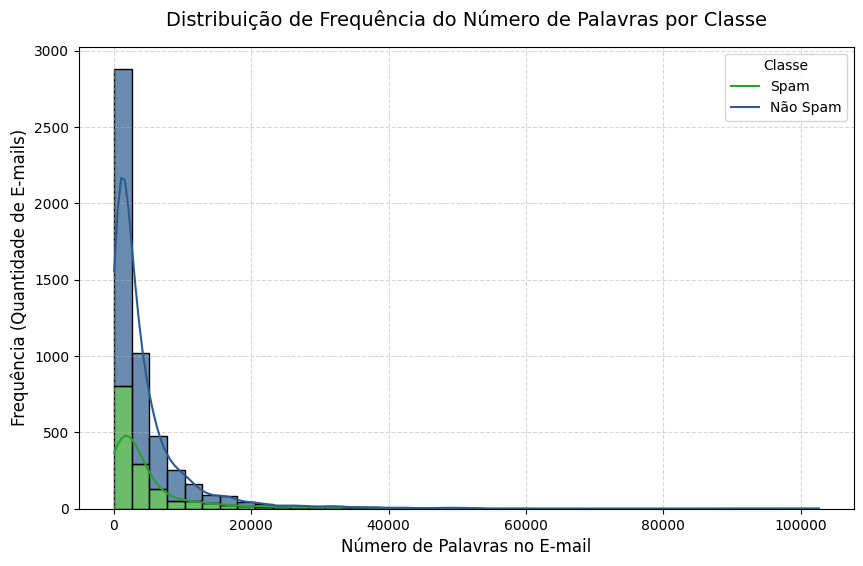

In [24]:
# 1. Remover as colunas que não representam contagem de palavras
colunas_metadados = ['Email No.', 'Prediction']
palavras_apenas = df.drop(columns=[col for col in colunas_metadados if col in df.columns])

# 2. Somar os termos de cada linha (e-mail) para obter o total de palavras de cada um
df['Total_Palavras'] = palavras_apenas.sum(axis=1)

# 3. Gerar o histograma de frequência distinguindo Spam vs Não Spam
plt.figure(figsize=(10, 6), facecolor='white')
sbs.histplot(data=df, x='Total_Palavras', hue='Prediction', bins=40, kde=True,
             palette={0: '#2b5c8f', 1: '#2ca02c'}, multiple='stack', alpha=0.7)

plt.title('Distribuição de Frequência do Número de Palavras por Classe', fontsize=14, pad=15)
plt.xlabel('Número de Palavras no E-mail', fontsize=12)
plt.ylabel('Frequência (Quantidade de E-mails)', fontsize=12)
plt.legend(title='Classe', labels=['Spam', 'Não Spam'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

* Mais de 95% dos emails se concentram até 20000 palavras.

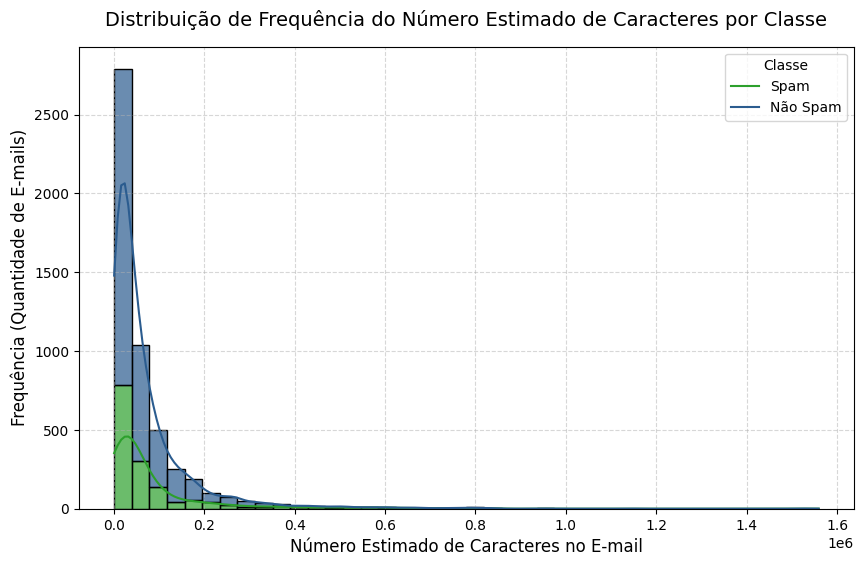

In [25]:
# 1. Obter o comprimento (número de caracteres) de cada palavra (nome das colunas)
comprimento_palavras = np.array([len(col) for col in palavras_apenas.columns])

# 2. Calcular o total de caracteres estimado para cada e-mail (linha)
df['Total_Caracteres_Estimado'] = palavras_apenas.values.dot(comprimento_palavras)

# 3. Gerar o histograma de frequência para caracteres distinguindo Spam vs Não Spam
plt.figure(figsize=(10, 6), facecolor='white')
sbs.histplot(data=df, x='Total_Caracteres_Estimado', hue='Prediction', bins=40, kde=True,
             palette={0: '#2b5c8f', 1: '#2ca02c'}, multiple='stack', alpha=0.7)

plt.title('Distribuição de Frequência do Número Estimado de Caracteres por Classe', fontsize=14, pad=15)
plt.xlabel('Número Estimado de Caracteres no E-mail', fontsize=12)
plt.ylabel('Frequência (Quantidade de E-mails)', fontsize=12)
plt.legend(title='Classe', labels=['Spam', 'Não Spam'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

* Mais de 95% dos emails têm até 10000 caracteres.

<Figure size 640x480 with 0 Axes>

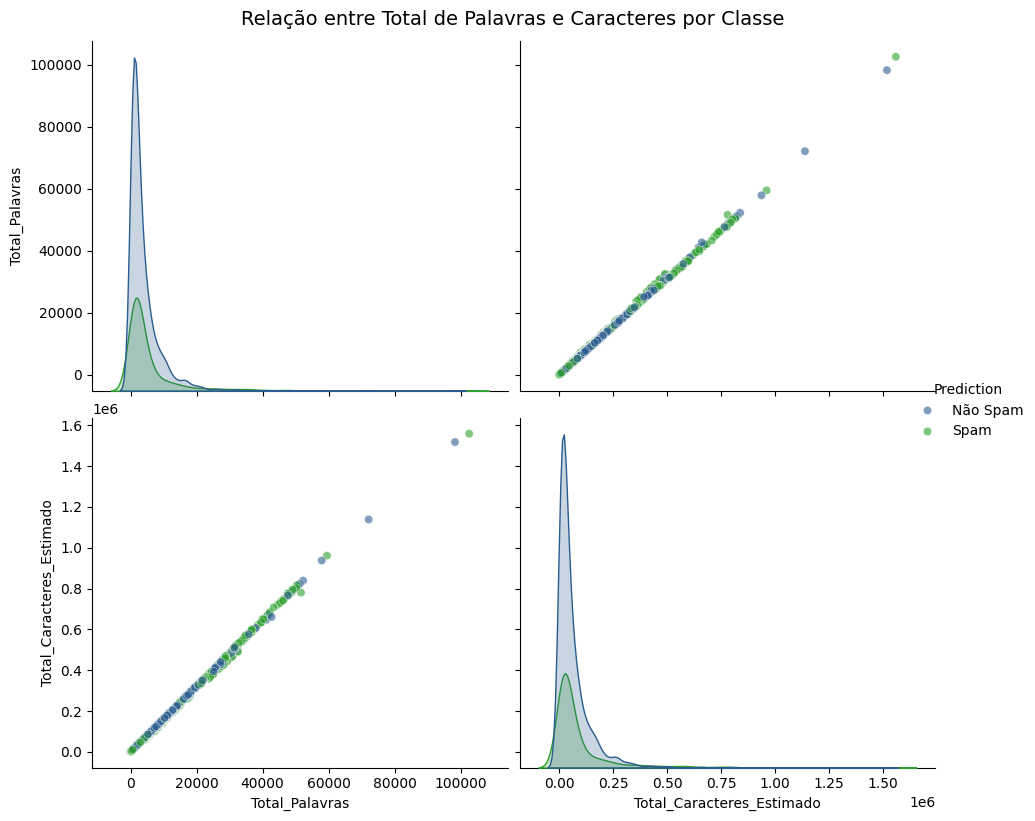

In [26]:
# Gerar um pair plot entre o total de palavras e o total estimado de caracteres
plt.figure(facecolor='white')

# Criando o pairplot utilizando as duas variáveis métricas e a classe de predição
g = sbs.pairplot(data=df,
                 vars=['Total_Palavras', 'Total_Caracteres_Estimado'],
                 hue='Prediction',
                 palette={0: '#2b5c8f', 1: '#2ca02c'},
                 height=4,
                 aspect=1.2,
                 plot_kws={'alpha': 0.6})

# Ajustando o título geral e as legendas para português
g.fig.suptitle('Relação entre Total de Palavras e Caracteres por Classe', y=1.02, fontsize=14)
new_labels = ['Não Spam', 'Spam']
for t, l in zip(g._legend.texts, new_labels):
    t.set_text(l)

plt.show()

* Correlação linear quase perfeita: indica que proporcionalmente, quanto mais palavras um email tem, mais caracteres ele tende a ter.
* Emails classificados como não spam tendem a ter uma base de abrangência maior para quantidade de palavras que os spam.
* Emails spam tendem a ter menos palavras.

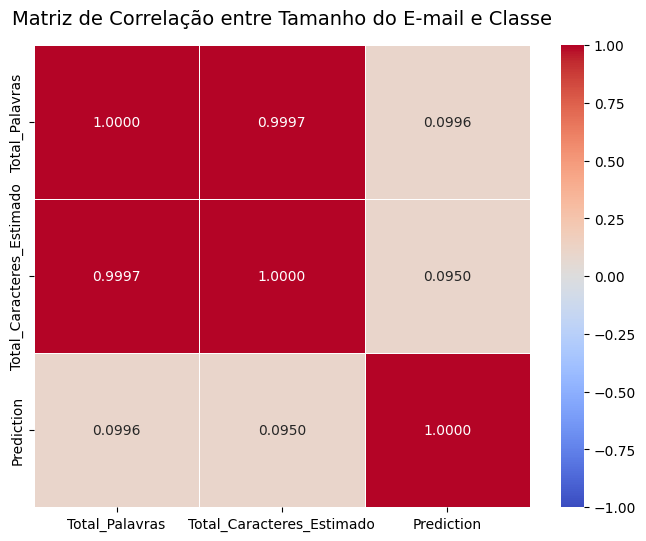

In [29]:
# 1. Selecionar apenas as variáveis de interesse
colunas_correlacao = ['Total_Palavras', 'Total_Caracteres_Estimado', 'Prediction']
matriz_corr = df[colunas_correlacao].corr()

# 3. Criar a representação visual usando um Heatmap
plt.figure(figsize=(8, 6), facecolor='white')
sbs.heatmap(matriz_corr,
            annot=True,
            cmap='coolwarm',
            fmt='.4f',
            linewidths=0.5,
            vmin=-1,
            vmax=1)

plt.title('Matriz de Correlação entre Tamanho do E-mail e Classe', fontsize=14, pad=15)
plt.show()

* E-mails de spam e e-mails legítimos (não spam) podem ter tamanhos idênticos de texto, de modo que olhar apenas para as variáveis consolidadas de contagem (como Total_Palavras ou Total_Caracteres_Estimado) isoladamente de fato não discrimina as classes.
* O verdadeiro poder preditivo está no padrão de presença e ausência de palavras específicas (ex: palavras urgentes de promoção, ganhos financeiros ou termos corporativos específicos)

# Modelo

In [28]:
from sklearn.model_selection import train_test_split

# 1. Definir as variáveis preditoras (X) e a variável alvo (y)
# Removemos metadados e as variáveis criadas por nós que não ajudam na diferenciação direta individual das palavras
colunas_para_remover = ['Email No.', 'Prediction', 'Total_Palavras', 'Total_Caracteres_Estimado']
X = df.drop(columns=[col for col in colunas_para_remover if col in df.columns])
y = df['Prediction']

# 2. Dividir em treino (80%) e teste (20%) mantendo a proporção de classes (stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Tamanho do conjunto de Treino: {X_train.shape[0]} e-mails")
print(f"Tamanho do conjunto de Teste: {X_test.shape[0]} e-mails\n")
print("Proporção de Spam no Treino:\n", y_train.value_counts(normalize=True))
print("\nProporção de Spam no Teste:\n", y_test.value_counts(normalize=True))

Tamanho do conjunto de Treino: 4137 e-mails
Tamanho do conjunto de Teste: 1035 e-mails

Proporção de Spam no Treino:
 Prediction
0    0.709935
1    0.290065
Name: proportion, dtype: float64

Proporção de Spam no Teste:
 Prediction
0    0.710145
1    0.289855
Name: proportion, dtype: float64


   RELATÓRIO DE CLASSIFICAÇÃO: NAIVE BAYES
              precision    recall  f1-score   support

    Não Spam       0.98      0.94      0.96       735
        Spam       0.87      0.94      0.90       300

    accuracy                           0.94      1035
   macro avg       0.92      0.94      0.93      1035
weighted avg       0.94      0.94      0.94      1035

   RELATÓRIO DE CLASSIFICAÇÃO: REGRESSÃO LOGÍSTICA
              precision    recall  f1-score   support

    Não Spam       0.99      0.98      0.99       735
        Spam       0.95      0.98      0.97       300

    accuracy                           0.98      1035
   macro avg       0.97      0.98      0.98      1035
weighted avg       0.98      0.98      0.98      1035



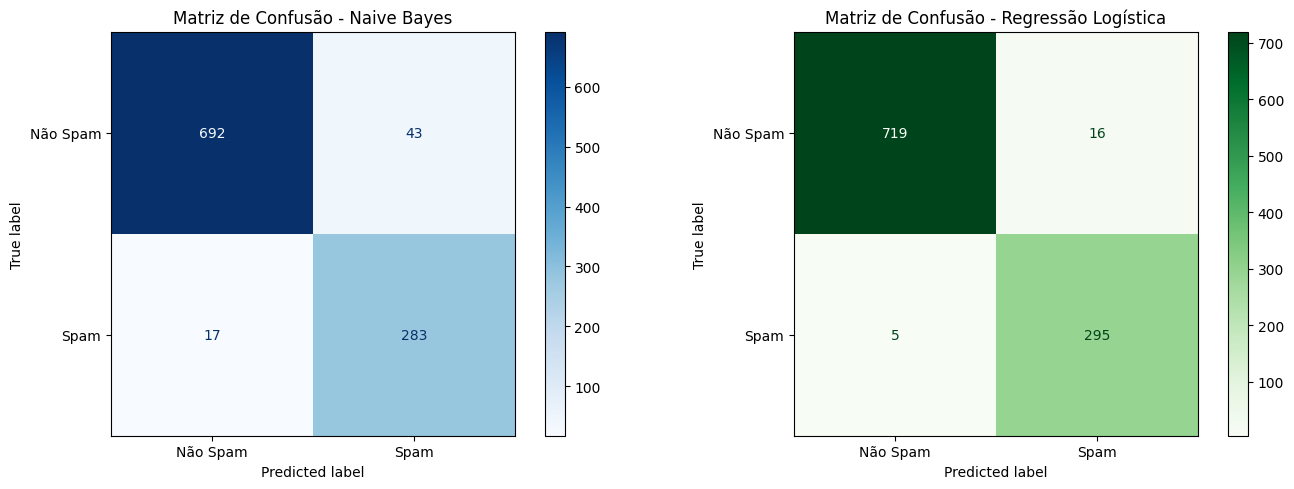

In [31]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Instanciar os Modelos
nb_model = MultinomialNB()
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# 2. Treinar os Modelos
nb_model.fit(X_train, y_train)
lr_model.fit(X_train, y_train)

# 3. Fazer Predições
y_pred_nb = nb_model.predict(X_test)
y_pred_lr = lr_model.predict(X_test)

# 4. Avaliação do Naive Bayes
print("==" * 25)
print("   RELATÓRIO DE CLASSIFICAÇÃO: NAIVE BAYES")
print("==" * 25)
print(classification_report(y_test, y_pred_nb, target_names=['Não Spam', 'Spam']))

# 5. Avaliação da Regressão Logística
print("==" * 25)
print("   RELATÓRIO DE CLASSIFICAÇÃO: REGRESSÃO LOGÍSTICA")
print("==" * 25)
print(classification_report(y_test, y_pred_lr, target_names=['Não Spam', 'Spam']))

# 6. Plotar as Matrizes de Confusão lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5), facecolor='white')

# Matriz Naive Bayes
cm_nb = confusion_matrix(y_test, y_pred_nb)
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=['Não Spam', 'Spam'])
disp_nb.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Matriz de Confusão - Naive Bayes')

# Matriz Regressão Logística
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Não Spam', 'Spam'])
disp_lr.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title('Matriz de Confusão - Regressão Logística')

plt.tight_layout()
plt.show()

# Resultados

# Conclusão